# Natural Counterfactual Causal Tracing (A100)

This notebook turns the advisor's mechanistic-interpretability question into a standard activation-patching case study.

[实验设置与运行说明](../../../docs/experiment_notes/09_appendix_factor_routes/a8c2ca3d9a8ea1f4.md)


In [1]:
# Run this helper once. Every later code cell uses %%cell_progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 16 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 16 tracked cells.


## 1. Setup

The pair sampling, layer grid, patch scopes, controls, and analysis metrics are written to Drive before model weights are loaded.


In [2]:
%%cell_progress 1/16 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/16 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/16 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])
cell_stage('Installing VisualTorque toolkit')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-e', str(TOOLKIT_ROOT)
])
SRC_ROOT = TOOLKIT_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))
importlib.invalidate_caches()

import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit:', visual_torque_toolkit.__file__)


Install and verify the multimodal environment:   6%|6         | 1/16 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/16 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  12%|#2        | 2/16 [00:00<?, ?cell/s]

NVIDIA A100-SXM4-40GB
CUDA memory (GB): 39.5
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/16 Lock the natural counterfactual tracing protocol
cell_stage('Writing protocol identity before pair selection')
import hashlib
import json
from datetime import datetime, timezone

# Run 1 (recommended pilot).
MODEL_ID = 'Qwen/Qwen3.5-9B'

# Run 2: uncomment in a fresh runtime only after Qwen passes the smoke test.
# MODEL_ID = 'google/gemma-4-12B-it'

MODEL_SPECS = {
    'Qwen/Qwen3.5-9B': {
        'slug': 'Qwen__Qwen3.5-9B',
        'expected_selected_layer': 13,
    },
    'google/gemma-4-12B-it': {
        'slug': 'google__gemma-4-12B-it',
        'expected_selected_layer': 7,
    },
}
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
SEED = 20260821
PAIRS_PER_EDIT = 8
EDIT_TYPES = ('add_unit', 'move_stack', 'redecompose', 'mirror')
MATCHED_PATCH_SCOPES = ('image_tokens', 'other_text_tokens', 'final_prompt_token')
BOOTSTRAP_REPLICATES = 3000
NATURAL_EFFECT_EPS = 0.02
IMAGE_TOKEN_ID_OVERRIDE = None  # int or list[int] only if automatic detection fails

spec = MODEL_SPECS[MODEL_ID]
MODEL_ROOT = PROJECT_ROOT / 'results' / spec['slug']
DISCOVERY_ROOT = MODEL_ROOT / 'activation_discovery_v1'
OUTPUT_ROOT = MODEL_ROOT / 'natural_counterfactual_causal_tracing_v1'
SHARD_DIR = OUTPUT_ROOT / 'pair_shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
SHARD_DIR.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'protocol_lock.json'

protocol_identity = {
    'schema_version': 'natural-counterfactual-causal-tracing-1.0',
    'analysis_status': 'frozen_exploratory_mechanistic_followup',
    'model_id': MODEL_ID,
    'pair_split': 'intervention_test',
    'edit_types': list(EDIT_TYPES),
    'pairs_per_edit': PAIRS_PER_EDIT,
    'outcome_change_policy': {
        'add_unit': 'require_change',
        'move_stack': 'require_change',
        'mirror': 'require_change',
        'redecompose': 'require_preservation',
    },
    'option_permutation_policy': 'stable_hash_balanced_over_six_permutations',
    'layer_policy': (
        'decoder-depth deciles plus selected representation layer and its neighbors'
    ),
    'matched_patch_scopes': list(MATCHED_PATCH_SCOPES),
    'image_token_id_override': IMAGE_TOKEN_ID_OVERRIDE,
    'control_donors': [
        'unrelated_same_source_outcome_final_token',
        'unrelated_same_target_outcome_final_token_when_outcomes_differ',
        'all-valid-token source/target ceiling and self-patch parity in smoke test',
    ],
    'primary_metric': (
        'projection of patched centered semantic-logprob vector onto the '
        'natural matched source-minus-target semantic-logprob vector'
    ),
    'secondary_metrics': [
        'raw centered semantic-logprob patch-effect norm',
        'source-answer contrast gain for outcome-changing pairs',
        'image-to-final-token recovery crossover by layer',
        'matched-minus-unrelated control recovery',
        'target/source final-token activation distance by layer',
    ],
    'natural_effect_epsilon': NATURAL_EFFECT_EPS,
    'bootstrap_unit': 'counterfactual_pair',
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'seed': SEED,
    'interpretation_limit': (
        'Natural activation patching supports a causal pathway account, but does '
        'not prove a unique circuit, full mediation, or perfectly on-manifold hybrids.'
    ),
}

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Existing protocol differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })
print('Model:', MODEL_ID)
print('Protocol:', PROTOCOL_LOCK_PATH)
print('Planned pairs:', PAIRS_PER_EDIT * len(EDIT_TYPES))


Lock the natural counterfactual tracing protocol:  19%|#8        | 3/16 [00:00<?, ?cell/s]

Model: Qwen/Qwen3.5-9B
Protocol: /content/drive/MyDrive/VisualTorque/results/Qwen__Qwen3.5-9B/natural_counterfactual_causal_tracing_v1/protocol_lock.json
Planned pairs: 32


In [6]:
%%cell_progress 5/16 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  25%|##5       | 4/16 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


## 2. Select counterfactual pairs and load the frozen model

`intervention_test` is used as its own pair-level split.


In [7]:
%%cell_progress 6/16 Select balanced natural counterfactual pairs
cell_stage('Loading scenes, pairs, and outcome examples')
from collections import Counter, defaultdict

from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

scene_records = read_jsonl(DATASET_DIR / 'scenes.jsonl')
pair_records = read_jsonl(DATASET_DIR / 'counterfactual_pairs.jsonl')
scene_by_id = {str(row['scene_id']): row for row in scene_records}

discovery_config_path = DISCOVERY_ROOT / 'capture_config.json'
discovery_selection_path = (
    DISCOVERY_ROOT / 'probe_results' / 'discovery_selection.json'
)
for required in (discovery_config_path, discovery_selection_path):
    assert required.is_file(), f'Missing prerequisite: {required}'
discovery_config = json.loads(
    discovery_config_path.read_text(encoding='utf-8')
)
discovery_identity = discovery_config['identity']
MODEL_REVISION = str(discovery_identity['resolved_revision'])
discovery_selection = json.loads(
    discovery_selection_path.read_text(encoding='utf-8')
)
SELECTED_LAYER_INDEX = int(
    discovery_selection['candidate_net_torque_layer']['layer_index']
)
assert SELECTED_LAYER_INDEX == spec['expected_selected_layer']

example_config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=Path('/content/unused_counterfactual_tracing'),
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    splits=('probe_train', 'probe_dev', 'probe_test'),
    batch_size=1,
    generation_every=0,
    seed=SEED,
)
all_examples = tuple(load_behavior_examples(example_config))
example_by_scene_variant = {
    (str(example.scene_id), str(example.variant)): example
    for example in all_examples
}
assert len(example_by_scene_variant) == 6 * len(scene_records)

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value}'.encode('utf-8')).hexdigest()

def transition_key(pair):
    target = scene_by_id[str(pair['target_scene_id'])]
    source = scene_by_id[str(pair['source_scene_id'])]
    return (
        str(target['problem_type']),
        str(source['problem_type']),
        f"{pair['target_outcome']}->{pair['source_outcome']}",
        int(np.sign(int(pair['delta_net_torque']))),
    )

def round_robin_strata(rows, count):
    groups = defaultdict(list)
    for row in rows:
        groups[transition_key(row)].append(row)
    for values in groups.values():
        values.sort(key=lambda row: stable_key(row['pair_id']))
    keys = sorted(groups, key=str)
    cursor = {key: 0 for key in keys}
    selected = []
    while len(selected) < min(count, len(rows)):
        changed = False
        for key in keys:
            index = cursor[key]
            if index < len(groups[key]) and len(selected) < count:
                selected.append(groups[key][index])
                cursor[key] += 1
                changed = True
        if not changed:
            break
    return selected

selected_pairs = []
for edit_type in EDIT_TYPES:
    candidates = [
        row for row in pair_records
        if row['split'] == 'intervention_test'
        and row['edit_type'] == edit_type
    ]
    if edit_type == 'redecompose':
        candidates = [
            row for row in candidates
            if row['source_outcome'] == row['target_outcome']
            and int(row['delta_net_torque']) == 0
        ]
    else:
        candidates = [
            row for row in candidates
            if row['source_outcome'] != row['target_outcome']
        ]
    chosen = round_robin_strata(candidates, PAIRS_PER_EDIT)
    assert len(chosen) == PAIRS_PER_EDIT, (edit_type, len(chosen))
    selected_pairs.extend(chosen)

def select_control_scene(reference_scene_id, desired_outcome, variant, excluded):
    reference = scene_by_id[str(reference_scene_id)]
    candidates = []
    for scene in scene_records:
        scene_id = str(scene['scene_id'])
        if scene_id in excluded:
            continue
        if str(scene['derived']['outcome']) != str(desired_outcome):
            continue
        same_problem = int(scene['problem_type'] == reference['problem_type'])
        torque_gap = abs(
            int(scene['derived']['net_torque'])
            - int(reference['derived']['net_torque'])
        )
        candidates.append((
            -same_problem, torque_gap, stable_key(
                f'control:{reference_scene_id}:{desired_outcome}:{variant}:{scene_id}'
            ), scene_id,
        ))
    assert candidates, (reference_scene_id, desired_outcome)
    candidates.sort()
    return candidates[0][-1]

pair_manifest = []
variant_counters = defaultdict(int)
for pair in sorted(selected_pairs, key=lambda row: row['pair_id']):
    edit_type = str(pair['edit_type'])
    variant_offset = int(
        stable_key('variant-offset:' + edit_type)[:8], 16
    ) % 6
    variant_index = (
        variant_offset + variant_counters[edit_type]
    ) % 6
    variant_counters[edit_type] += 1
    variant = f'permutation_{variant_index}'
    source_id = str(pair['source_scene_id'])
    target_id = str(pair['target_scene_id'])
    excluded = {source_id, target_id}
    same_source_id = select_control_scene(
        source_id, pair['source_outcome'], variant, excluded
    )
    excluded.add(same_source_id)
    same_target_id = None
    if pair['source_outcome'] != pair['target_outcome']:
        same_target_id = select_control_scene(
            target_id, pair['target_outcome'], variant, excluded
        )
    source_scene = scene_by_id[source_id]
    target_scene = scene_by_id[target_id]
    pair_manifest.append({
        'pair_id': str(pair['pair_id']),
        'edit_type': str(pair['edit_type']),
        'equivalence_key': str(pair['equivalence_key']),
        'changed_stack_ids': list(pair['changed_stack_ids']),
        'delta_net_torque': int(pair['delta_net_torque']),
        'source_scene_id': source_id,
        'target_scene_id': target_id,
        'source_outcome': str(pair['source_outcome']),
        'target_outcome': str(pair['target_outcome']),
        'source_problem_type': str(source_scene['problem_type']),
        'target_problem_type': str(target_scene['problem_type']),
        'source_left_torque': int(source_scene['derived']['left_torque']),
        'source_right_torque': int(source_scene['derived']['right_torque']),
        'target_left_torque': int(target_scene['derived']['left_torque']),
        'target_right_torque': int(target_scene['derived']['right_torque']),
        'source_left_units': int(source_scene['derived']['left_units']),
        'source_right_units': int(source_scene['derived']['right_units']),
        'target_left_units': int(target_scene['derived']['left_units']),
        'target_right_units': int(target_scene['derived']['right_units']),
        'variant': variant,
        'same_source_outcome_control_scene_id': same_source_id,
        'same_target_outcome_control_scene_id': same_target_id,
    })

manifest_path = OUTPUT_ROOT / 'pair_manifest.jsonl'
temporary_manifest = manifest_path.with_suffix('.jsonl.tmp')
with temporary_manifest.open('w', encoding='utf-8') as handle:
    for row in pair_manifest:
        handle.write(json.dumps(row, sort_keys=True) + '\n')
temporary_manifest.replace(manifest_path)

selected_scene_ids = set()
for row in pair_manifest:
    selected_scene_ids.update({
        row['source_scene_id'], row['target_scene_id'],
        row['same_source_outcome_control_scene_id'],
    })
    if row['same_target_outcome_control_scene_id'] is not None:
        selected_scene_ids.add(row['same_target_outcome_control_scene_id'])
selected_examples = {
    (scene_id, row['variant']): example_by_scene_variant[(scene_id, row['variant'])]
    for row in pair_manifest
    for scene_id in (
        row['source_scene_id'], row['target_scene_id'],
        row['same_source_outcome_control_scene_id'],
        *(() if row['same_target_outcome_control_scene_id'] is None else (
            row['same_target_outcome_control_scene_id'],
        )),
    )
}
print('Selected pairs:', len(pair_manifest))
print('Edit types:', Counter(row['edit_type'] for row in pair_manifest))
print('Variants:', Counter(row['variant'] for row in pair_manifest))
print('Target problem types:', Counter(
    row['target_problem_type'] for row in pair_manifest
))


Select balanced natural counterfactual pairs:  31%|###1      | 5/16 [00:00<?, ?cell/s]

Selected pairs: 32
Edit types: Counter({'redecompose': 8, 'add_unit': 8, 'mirror': 8, 'move_stack': 8})
Variants: Counter({'permutation_5': 6, 'permutation_0': 6, 'permutation_2': 6, 'permutation_1': 5, 'permutation_3': 5, 'permutation_4': 4})
Target problem types: Counter({'conflict_balance': 12, 'compatible_weight_distance': 9, 'balance': 5, 'multi_stack': 2, 'conflict_distance': 1, 'conflict_weight': 1, 'weight': 1, 'distance': 1})


In [8]:
%%cell_progress 7/16 Load the pinned model and resolve the layer grid
cell_stage('Loading processor and pinned model weights')
adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=MODEL_DTYPE,
    device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = [
        discovery_identity.get('layer_path'),
        'model.language_model.layers',
        'model.text_model.layers',
        'language_model.model.layers',
        'language_model.layers',
        'model.model.layers',
        'model.layers',
    ]
    failures = []
    for path in candidates:
        if not path:
            continue
        try:
            layers = resolve_module_path(model, path)
        except (AttributeError, KeyError) as exc:
            failures.append(f'{path}: {exc}')
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
        failures.append(f'{path}: {type(layers).__name__}')
    raise RuntimeError('Could not locate decoder layers:\n' + '\n'.join(failures))

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
layer_count = len(DECODER_LAYERS)
quantile_layers = {
    int(round(value))
    for value in np.linspace(0, layer_count - 1, 9)
}
PATCH_LAYERS = sorted(
    quantile_layers
    | {
        SELECTED_LAYER_INDEX - 1,
        SELECTED_LAYER_INDEX,
        SELECTED_LAYER_INDEX + 1,
    }
)
PATCH_LAYERS = [
    layer for layer in PATCH_LAYERS if 0 <= layer < layer_count
]
resolved_now = adapter.metadata.get('resolved_revision')
if resolved_now is not None:
    assert str(resolved_now) == MODEL_REVISION
print('Layer path:', LAYER_PATH)
print('Decoder layers:', layer_count)
print('Selected representation layer:', SELECTED_LAYER_INDEX)
print('Causal tracing grid:', PATCH_LAYERS)


Load the pinned model and resolve the layer grid:  38%|###7      | 6/16 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-9B',
 'requested_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'resolved_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 9409813744,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Decoder layers: 32
Selected representation layer: 13
Causal tracing grid: [0, 4, 8, 12, 13, 14, 16, 19, 23, 27, 31]


## 3. Natural activation patching

All paired prompts use the same option permutation, so their token IDs, attention mask, and image-token layout must match exactly.


In [9]:
%%cell_progress 8/16 Define aligned preparation, capture, and patching
cell_stage('Defining hidden-state and semantic-score utilities')
import math

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported decoder output: {type(output).__name__}')
    if hidden.ndim != 3:
        raise ValueError(f'Expected [batch, sequence, hidden], got {hidden.shape}')
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(
        'Decoder output object is not safely replaceable: '
        + type(output).__name__
    )

def prepare_example(example):
    plan = adapter._candidate_plan(example)
    if plan is None:
        raise RuntimeError('Tracing requires single-token A/B/C labels.')
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(
            adapter._template([example.messages()], add_generation_prompt=True)
        ),
        fixed_prefix,
    )
    return {
        'example': example,
        'inputs': inputs,
        'token_by_label': token_by_label,
    }

def flatten_integer_values(value):
    if value is None:
        return []
    if isinstance(value, (int, np.integer)):
        return [int(value)]
    if isinstance(value, (tuple, list, set)):
        result = []
        for item in value:
            result.extend(flatten_integer_values(item))
        return result
    return []

def discover_image_mask(prepared):
    inputs = prepared['inputs']
    input_ids = inputs['input_ids'][0].detach().cpu()
    attention = inputs.get('attention_mask')
    valid = (
        attention[0].detach().cpu().bool()
        if attention is not None
        else torch.ones_like(input_ids, dtype=torch.bool)
    )
    candidate_ids = set(flatten_integer_values(IMAGE_TOKEN_ID_OVERRIDE))
    for owner in (
        getattr(adapter, 'processor', None),
        getattr(adapter, 'model', None),
        getattr(getattr(adapter, 'model', None), 'config', None),
    ):
        if owner is None:
            continue
        for name in (
            'image_token_id', 'image_token_ids', 'image_token_index',
            'vision_token_id', 'vision_token_ids',
        ):
            candidate_ids.update(flatten_integer_values(getattr(owner, name, None)))
    tokenizer = getattr(adapter.processor, 'tokenizer', adapter.processor)
    tokens = tokenizer.convert_ids_to_tokens(input_ids.tolist())
    for token_id, token_text in zip(input_ids.tolist(), tokens):
        lower = str(token_text).lower()
        if any(marker in lower for marker in ('image', 'vision', '<img', 'img>')):
            candidate_ids.add(int(token_id))
    image = torch.tensor(
        [int(token_id) in candidate_ids for token_id in input_ids.tolist()],
        dtype=torch.bool,
    ) & valid
    if not bool(image.any()):
        token_counts = Counter(str(token) for token in tokens)
        repeated_specials = token_counts.most_common(20)
        raise RuntimeError(
            'Could not detect image-token positions. Inspect repeated tokens below '
            'and set IMAGE_TOKEN_ID_OVERRIDE before model load: '
            + repr(repeated_specials)
        )
    final_index = int(torch.where(valid)[0][-1])
    final = torch.zeros_like(valid)
    final[final_index] = True
    other_text = valid & ~image & ~final
    assert bool(other_text.any()) and not bool(image[final_index])
    return {
        'valid_tokens': valid,
        'image_tokens': image,
        'other_text_tokens': other_text,
        'final_prompt_token': final,
        'tokens': tokens,
        'candidate_image_token_ids': sorted(candidate_ids),
    }

def assert_aligned(source_prepared, target_prepared):
    source_inputs = source_prepared['inputs']
    target_inputs = target_prepared['inputs']
    for key in ('input_ids', 'attention_mask'):
        if key in source_inputs or key in target_inputs:
            assert key in source_inputs and key in target_inputs
            assert torch.equal(source_inputs[key], target_inputs[key]), key
    source_masks = discover_image_mask(source_prepared)
    target_masks = discover_image_mask(target_prepared)
    for scope in ('valid_tokens',) + MATCHED_PATCH_SCOPES:
        assert torch.equal(source_masks[scope], target_masks[scope]), scope
    return target_masks

def semantic_record(example, logits, token_by_label):
    next_logprobs = torch.log_softmax(logits[0, -1, :].float(), dim=-1)
    label_scores = {
        label: float(next_logprobs[token_by_label[label]].detach().cpu())
        for label in example.labels
    }
    semantic_scores = {
        str(example.label_to_semantic[label]): label_scores[label]
        for label in example.labels
    }
    predicted_label = max(sorted(example.labels), key=lambda key: label_scores[key])
    return {
        'scene_id': str(example.scene_id),
        'example_id': str(example.example_id),
        'variant': str(example.variant),
        'gold_outcome': str(example.gold_semantic),
        'predicted_semantic': str(example.label_to_semantic[predicted_label]),
        'correct': str(example.label_to_semantic[predicted_label]) == str(example.gold_semantic),
        'logprob_left': semantic_scores['left'],
        'logprob_right': semantic_scores['right'],
        'logprob_balanced': semantic_scores['balanced'],
    }

def forward_capture(prepared, layers=PATCH_LAYERS):
    captured = {}
    handles = []
    for layer_index in layers:
        def hook(_module, _inputs, output, layer_index=layer_index):
            captured[layer_index] = (
                output_hidden_tensor(output)[0].detach().cpu().clone()
            )
        handles.append(DECODER_LAYERS[layer_index].register_forward_hook(hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    assert set(captured) == set(layers)
    score = semantic_record(
        prepared['example'], output.logits, prepared['token_by_label']
    )
    return score, captured

def forward_patch(target_prepared, donor_hidden, layer_index, patch_mask):
    audit = {}
    layer = DECODER_LAYERS[int(layer_index)]

    def patch_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        donor = donor_hidden.to(device=hidden.device, dtype=hidden.dtype)
        mask = patch_mask.to(device=hidden.device)
        assert hidden.shape[0] == 1
        assert hidden.shape[1:] == donor.shape
        assert mask.shape == (hidden.shape[1],)
        modified = hidden.clone()
        modified[:, mask, :] = donor[mask, :].unsqueeze(0)
        audit['patched_tokens'] = int(mask.sum().item())
        return replace_output_hidden(output, modified)

    handle = layer.register_forward_hook(patch_hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**target_prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    record = semantic_record(
        target_prepared['example'], output.logits,
        target_prepared['token_by_label'],
    )
    record['patched_tokens'] = audit['patched_tokens']
    return record

print('Natural activation-patching functions ready.')


Define aligned preparation, capture, and patching:  44%|####3     | 7/16 [00:00<?, ?cell/s]

Natural activation-patching functions ready.


In [10]:
%%cell_progress 9/16 Run mandatory alignment, parity, and ceiling smoke tests
cell_stage('Preparing the first matched counterfactual pair')
smoke_pair = pair_manifest[0]
smoke_variant = smoke_pair['variant']
smoke_source = prepare_example(example_by_scene_variant[
    (smoke_pair['source_scene_id'], smoke_variant)
])
smoke_target = prepare_example(example_by_scene_variant[
    (smoke_pair['target_scene_id'], smoke_variant)
])
smoke_masks = assert_aligned(smoke_source, smoke_target)
smoke_layer = SELECTED_LAYER_INDEX

cell_stage('Capturing source and target natural activations')
source_score, source_hidden = forward_capture(smoke_source, [smoke_layer])
target_score, target_hidden = forward_capture(smoke_target, [smoke_layer])

cell_stage('Checking target-to-target self-patch parity')
self_score = forward_patch(
    smoke_target, target_hidden[smoke_layer], smoke_layer,
    smoke_masks['valid_tokens'],
)
cell_stage('Checking source-to-target all-token ceiling')
ceiling_score = forward_patch(
    smoke_target, source_hidden[smoke_layer], smoke_layer,
    smoke_masks['valid_tokens'],
)
score_columns = ('logprob_left', 'logprob_right', 'logprob_balanced')
self_error = max(
    abs(self_score[name] - target_score[name]) for name in score_columns
)
ceiling_error = max(
    abs(ceiling_score[name] - source_score[name]) for name in score_columns
)
assert self_error < 5e-3, ('self patch parity failed', self_error)
assert ceiling_error < 5e-3, ('all-token ceiling failed', ceiling_error)

mask_summary = {
    key: int(smoke_masks[key].sum())
    for key in ('valid_tokens',) + MATCHED_PATCH_SCOPES
}
print('Aligned input length:', len(smoke_masks['valid_tokens']))
print('Patch token counts:', mask_summary)
print('Detected image token IDs:', smoke_masks['candidate_image_token_ids'])
print('Self-patch max error:', self_error)
print('All-token ceiling max error:', ceiling_error)
print('Smoke test passed.')
del smoke_source, smoke_target, source_hidden, target_hidden
torch.cuda.empty_cache()


Run mandatory alignment, parity, and ceiling smoke tests:  50%|#####     | 8/16 [00:00<?, ?cell/s]

Aligned input length: 530
Patch token counts: {'valid_tokens': 530, 'image_tokens': 394, 'other_text_tokens': 135, 'final_prompt_token': 1}
Detected image token IDs: [248053, 248054, 248056]
Self-patch max error: 0.0
All-token ceiling max error: 0.0
Smoke test passed.


In [11]:
%%cell_progress 10/16 Freeze capture identity and estimate run size
cell_stage('Hashing immutable inputs')

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

outcome_changing_pairs = sum(
    row['source_outcome'] != row['target_outcome']
    for row in pair_manifest
)
expected_patches = (
    len(pair_manifest) * len(PATCH_LAYERS)
    * (len(MATCHED_PATCH_SCOPES) + 1)
    + outcome_changing_pairs * len(PATCH_LAYERS)
)
capture_identity = {
    'schema_version': 'natural-counterfactual-capture-1.0',
    'model_id': MODEL_ID,
    'resolved_revision': MODEL_REVISION,
    'dtype': MODEL_DTYPE,
    'dataset_fingerprint': example_config.dataset_fingerprint(),
    'protocol_lock_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'pair_manifest_sha256': sha256_file(manifest_path),
    'discovery_capture_sha256': sha256_file(discovery_config_path),
    'discovery_selection_sha256': sha256_file(discovery_selection_path),
    'layer_path': LAYER_PATH,
    'decoder_layer_count': len(DECODER_LAYERS),
    'selected_layer_index': SELECTED_LAYER_INDEX,
    'patch_layers': PATCH_LAYERS,
    'matched_patch_scopes': list(MATCHED_PATCH_SCOPES),
    'detected_image_token_ids': smoke_masks['candidate_image_token_ids'],
    'smoke_patch_token_counts': mask_summary,
    'expected_pairs': len(pair_manifest),
    'expected_patch_records': expected_patches,
    'seed': SEED,
}
capture_config_path = OUTPUT_ROOT / 'capture_config.json'
if capture_config_path.is_file():
    previous = json.loads(capture_config_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == capture_identity, (
        'Existing capture differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(capture_config_path, {
        'identity': capture_identity,
        'adapter_metadata': adapter.metadata,
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
    })
CAPTURE_IDENTITY_SHA256 = sha256_file(capture_config_path)
print('Pairs:', len(pair_manifest))
print('Layers:', len(PATCH_LAYERS), PATCH_LAYERS)
print('Expected patched forwards:', expected_patches)
print('Resume directory:', SHARD_DIR)


Freeze capture identity and estimate run size:  56%|#####6    | 9/16 [00:00<?, ?cell/s]

Pairs: 32
Layers: 11 [0, 4, 8, 12, 13, 14, 16, 19, 23, 27, 31]
Expected patched forwards: 1672
Resume directory: /content/drive/MyDrive/VisualTorque/results/Qwen__Qwen3.5-9B/natural_counterfactual_causal_tracing_v1/pair_shards


In [12]:
%%cell_progress 11/16 Capture or resume all natural counterfactual patches
cell_stage('Reading completed pair shards')

def score_vector(record):
    return np.asarray([
        record['logprob_left'],
        record['logprob_right'],
        record['logprob_balanced'],
    ], dtype=np.float64)

def hidden_diagnostics(source_hidden, target_hidden, masks):
    rows = []
    for layer_index in PATCH_LAYERS:
        source = source_hidden[layer_index].float()
        target = target_hidden[layer_index].float()
        final_mask = masks['final_prompt_token']
        image_mask = masks['image_tokens']
        final_delta = source[final_mask] - target[final_mask]
        source_image_mean = source[image_mask].mean(dim=0)
        target_image_mean = target[image_mask].mean(dim=0)
        rows.append({
            'layer_index': int(layer_index),
            'final_token_delta_l2': float(final_delta.norm().item()),
            'image_mean_delta_l2': float(
                (source_image_mean - target_image_mean).norm().item()
            ),
            'final_source_norm': float(source[final_mask].norm().item()),
            'final_target_norm': float(target[final_mask].norm().item()),
        })
    return rows

completed_pair_ids = set()
for path in sorted(SHARD_DIR.glob('pair_*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == CAPTURE_IDENTITY_SHA256
    pair_id = str(payload['pair']['pair_id'])
    if pair_id in completed_pair_ids:
        raise RuntimeError(f'Duplicate pair shard: {pair_id}')
    completed_pair_ids.add(pair_id)
expected_pair_ids = {row['pair_id'] for row in pair_manifest}
assert completed_pair_ids <= expected_pair_ids
print('Completed pairs:', len(completed_pair_ids))

per_pair_forward_counts = {}
for row in pair_manifest:
    control_count = 1 + int(
        row['source_outcome'] != row['target_outcome']
    )
    per_pair_forward_counts[row['pair_id']] = (
        len(PATCH_LAYERS) * (len(MATCHED_PATCH_SCOPES) + control_count)
    )
completed_forwards = sum(
    per_pair_forward_counts[pair_id] for pair_id in completed_pair_ids
)
patch_progress = tqdm(
    total=sum(per_pair_forward_counts.values()),
    initial=completed_forwards,
    desc='Natural counterfactual patches', unit='forward',
    dynamic_ncols=True,
)

for pair_index, pair in enumerate(pair_manifest):
    pair_id = pair['pair_id']
    if pair_id in completed_pair_ids:
        continue
    patch_progress.set_postfix_str(
        f"{pair['edit_type']} | {pair_id}", refresh=True
    )
    variant = pair['variant']
    source_prepared = prepare_example(example_by_scene_variant[
        (pair['source_scene_id'], variant)
    ])
    target_prepared = prepare_example(example_by_scene_variant[
        (pair['target_scene_id'], variant)
    ])
    same_source_prepared = prepare_example(example_by_scene_variant[
        (pair['same_source_outcome_control_scene_id'], variant)
    ])
    same_target_prepared = None
    if pair['same_target_outcome_control_scene_id'] is not None:
        same_target_prepared = prepare_example(example_by_scene_variant[
            (pair['same_target_outcome_control_scene_id'], variant)
        ])

    masks = assert_aligned(source_prepared, target_prepared)
    assert_aligned(same_source_prepared, target_prepared)
    if same_target_prepared is not None:
        assert_aligned(same_target_prepared, target_prepared)

    source_score, source_hidden = forward_capture(source_prepared)
    target_score, target_hidden = forward_capture(target_prepared)
    same_source_score, same_source_hidden = forward_capture(same_source_prepared)
    same_target_score = None
    same_target_hidden = None
    if same_target_prepared is not None:
        same_target_score, same_target_hidden = forward_capture(same_target_prepared)

    baseline_records = {
        'source': source_score,
        'target': target_score,
        'unrelated_same_source_outcome': same_source_score,
        'unrelated_same_target_outcome': same_target_score,
    }
    patch_records = []
    for layer_index in PATCH_LAYERS:
        for scope in MATCHED_PATCH_SCOPES:
            record = forward_patch(
                target_prepared, source_hidden[layer_index],
                layer_index, masks[scope],
            )
            record.update({
                'layer_index': int(layer_index),
                'scope': scope,
                'donor_type': 'matched_source',
                'donor_scene_id': pair['source_scene_id'],
                'condition': f'matched_{scope}',
            })
            patch_records.append(record)
            patch_progress.update(1)

        record = forward_patch(
            target_prepared, same_source_hidden[layer_index],
            layer_index, masks['final_prompt_token'],
        )
        record.update({
            'layer_index': int(layer_index),
            'scope': 'final_prompt_token',
            'donor_type': 'unrelated_same_source_outcome',
            'donor_scene_id': pair['same_source_outcome_control_scene_id'],
            'condition': 'control_same_source_outcome_final',
        })
        patch_records.append(record)
        patch_progress.update(1)

        if same_target_prepared is not None:
            record = forward_patch(
                target_prepared, same_target_hidden[layer_index],
                layer_index, masks['final_prompt_token'],
            )
            record.update({
                'layer_index': int(layer_index),
                'scope': 'final_prompt_token',
                'donor_type': 'unrelated_same_target_outcome',
                'donor_scene_id': pair['same_target_outcome_control_scene_id'],
                'condition': 'control_same_target_outcome_final',
            })
            patch_records.append(record)
            patch_progress.update(1)

    payload = {
        'schema_version': 'natural-counterfactual-pair-shard-1.0',
        'capture_identity_sha256': CAPTURE_IDENTITY_SHA256,
        'pair': pair,
        'baselines': baseline_records,
        'activation_diagnostics': hidden_diagnostics(
            source_hidden, target_hidden, masks
        ),
        'patch_records': patch_records,
    }
    destination = SHARD_DIR / f'{pair_id}.json'
    write_json_atomic(destination, payload)
    completed_pair_ids.add(pair_id)

    del (
        source_prepared, target_prepared, same_source_prepared,
        source_hidden, target_hidden, same_source_hidden,
    )
    if same_target_prepared is not None:
        del same_target_prepared, same_target_hidden
    if (pair_index + 1) % 4 == 0:
        torch.cuda.empty_cache()

patch_progress.close()
assert completed_pair_ids == expected_pair_ids
write_json_atomic(OUTPUT_ROOT / 'capture_summary.json', {
    'completed_pairs': len(completed_pair_ids),
    'expected_pairs': len(expected_pair_ids),
    'completed_patch_records': sum(per_pair_forward_counts.values()),
    'patch_layers': PATCH_LAYERS,
})
print('Capture complete:', len(completed_pair_ids), 'pairs')


Capture or resume all natural counterfactual patches:  62%|######2   | 10/16 [00:00<?, ?cell/s]

Completed pairs: 0


Natural counterfactual patches:   0%|          | 0/1672 [00:00<?, ?forward/s]

Capture complete: 32 pairs


## 4. Causal analysis

The recovery metric operates on the three centered semantic log probabilities `[left, right, balanced]`.


In [13]:
%%cell_progress 12/16 Release GPU and assemble the causal tracing table
cell_stage('Releasing model memory')
del adapter
import gc
gc.collect()
torch.cuda.empty_cache()

cell_stage('Reading pair shards and deriving recovery metrics')
patch_rows = []
diagnostic_rows = []
baseline_rows = []
semantic_names = ('left', 'right', 'balanced')

def centered_vector(record):
    vector = np.asarray([
        record[f'logprob_{name}'] for name in semantic_names
    ], dtype=np.float64)
    return vector - vector.mean()

for path in tqdm(sorted(SHARD_DIR.glob('pair_*.json')), desc='Reading pair shards'):
    payload = json.loads(path.read_text(encoding='utf-8'))
    pair = payload['pair']
    source = payload['baselines']['source']
    target = payload['baselines']['target']
    source_vector = centered_vector(source)
    target_vector = centered_vector(target)
    natural_delta = source_vector - target_vector
    natural_norm = float(np.linalg.norm(natural_delta))
    denominator = float(np.dot(natural_delta, natural_delta))

    for role, record in payload['baselines'].items():
        if record is None:
            continue
        baseline_rows.append({
            **pair,
            'role': role,
            **record,
            'natural_effect_norm': natural_norm,
        })

    for diagnostic in payload['activation_diagnostics']:
        diagnostic_rows.append({**pair, **diagnostic})

    for record in payload['patch_records']:
        patched_vector = centered_vector(record)
        effect = patched_vector - target_vector
        recovery = None
        if natural_norm >= NATURAL_EFFECT_EPS:
            recovery = float(np.dot(effect, natural_delta) / denominator)
        effect_norm = float(np.linalg.norm(effect))
        source_answer_gain = None
        if pair['source_outcome'] != pair['target_outcome']:
            source_index = semantic_names.index(pair['source_outcome'])
            target_index = semantic_names.index(pair['target_outcome'])
            target_contrast = (
                target_vector[source_index] - target_vector[target_index]
            )
            patched_contrast = (
                patched_vector[source_index] - patched_vector[target_index]
            )
            source_answer_gain = float(patched_contrast - target_contrast)
        patch_rows.append({
            **pair,
            **record,
            'natural_effect_norm': natural_norm,
            'valid_recovery': recovery is not None,
            'recovery': recovery,
            'patch_effect_norm': effect_norm,
            'source_answer_contrast_gain': source_answer_gain,
            'source_prediction_recovered': (
                record['predicted_semantic'] == pair['source_outcome']
            ),
            'target_was_correct': bool(target['correct']),
            'source_was_correct': bool(source['correct']),
        })

patch_frame = pd.DataFrame(patch_rows)
diagnostic_frame = pd.DataFrame(diagnostic_rows)
baseline_frame = pd.DataFrame(baseline_rows)
assert len(patch_frame) == capture_identity['expected_patch_records']
assert patch_frame['pair_id'].nunique() == len(pair_manifest)
patch_frame.to_csv(ANALYSIS_DIR / 'patch_records.csv', index=False)
diagnostic_frame.to_csv(
    ANALYSIS_DIR / 'activation_diagnostics.csv', index=False
)
baseline_frame.to_csv(ANALYSIS_DIR / 'baseline_records.csv', index=False)
print('Patch records:', len(patch_frame))
print('Valid recovery:', Counter(patch_frame['valid_recovery']))
print('Natural effect norm by edit:')
display(
    patch_frame[
        ['pair_id', 'edit_type', 'natural_effect_norm']
    ].drop_duplicates('pair_id').groupby('edit_type')[
        'natural_effect_norm'
    ].describe()
)


Release GPU and assemble the causal tracing table:  69%|######8   | 11/16 [00:00<?, ?cell/s]

Reading pair shards:   0%|          | 0/32 [00:00<?, ?it/s]

Patch records: 1672
Valid recovery: Counter({True: 1672})
Natural effect norm by edit:


,count,mean,std,min,25%,50%,75%,max
edit_type,,,,,,,,
add_unit,8.0,1.835875,1.584666,0.367990,0.888912,1.437133,2.057004,5.248015
mirror,8.0,1.680342,0.962477,0.669266,0.714434,1.626670,2.583125,2.874094
move_stack,8.0,0.404591,0.297017,0.102062,0.204124,0.329870,0.454601,0.984251
redecompose,8.0,1.662920,1.121520,0.367990,0.604011,1.765973,2.373146,3.510401


In [14]:
%%cell_progress 13/16 Bootstrap layer-by-scope recovery curves
cell_stage('Computing pair-bootstrap confidence intervals')
rng = np.random.default_rng(SEED + 1000)

def bootstrap_mean_ci(frame, column, replicates=BOOTSTRAP_REPLICATES):
    values = frame.groupby('pair_id')[column].mean().dropna().to_numpy(dtype=float)
    if len(values) == 0:
        return {'n_pairs': 0, 'mean': np.nan, 'ci_low': np.nan, 'ci_high': np.nan}
    draws = rng.choice(values, size=(replicates, len(values)), replace=True).mean(axis=1)
    return {
        'n_pairs': int(len(values)),
        'mean': float(values.mean()),
        'ci_low': float(np.quantile(draws, 0.025)),
        'ci_high': float(np.quantile(draws, 0.975)),
    }

summary_rows = []
group_columns = ['edit_type', 'condition', 'layer_index']
for keys, group in patch_frame.groupby(group_columns, sort=True):
    recovery_stats = bootstrap_mean_ci(
        group[group['valid_recovery']], 'recovery'
    )
    effect_stats = bootstrap_mean_ci(group, 'patch_effect_norm')
    summary_rows.append({
        **dict(zip(group_columns, keys)),
        **{f'recovery_{key}': value for key, value in recovery_stats.items()},
        **{f'effect_norm_{key}': value for key, value in effect_stats.items()},
    })
layer_summary = pd.DataFrame(summary_rows)
layer_summary.to_csv(ANALYSIS_DIR / 'layer_summary.csv', index=False)

matched_summary = layer_summary[
    layer_summary['condition'].isin([
        'matched_image_tokens',
        'matched_other_text_tokens',
        'matched_final_prompt_token',
    ])
]
display(matched_summary.head(12))


Bootstrap layer-by-scope recovery curves:  75%|#######5  | 12/16 [00:00<?, ?cell/s]

,edit_type,condition,layer_index,recovery_n_pairs,recovery_mean,recovery_ci_low,recovery_ci_high,effect_norm_n_pairs,effect_norm_mean,effect_norm_ci_low,effect_norm_ci_high
22,add_unit,matched_final_prompt_token,0,8,0.034839,0.004057,0.071128,8,0.063789,2.551556e-02,0.089304
23,add_unit,matched_final_prompt_token,4,8,0.031152,-0.020543,0.105040,8,0.038273,7.604217e-08,0.076547
24,add_unit,matched_final_prompt_token,8,8,0.011065,-0.019864,0.041660,8,0.063789,2.551555e-02,0.089304
25,add_unit,matched_final_prompt_token,12,8,0.024133,-0.011630,0.063312,8,0.063789,2.551554e-02,0.089623
26,add_unit,matched_final_prompt_token,13,8,0.006980,-0.022551,0.035614,8,0.063789,2.551556e-02,0.089304
27,add_unit,matched_final_prompt_token,14,8,-0.001582,-0.027062,0.026610,8,0.051031,1.275777e-02,0.089304
28,add_unit,matched_final_prompt_token,16,8,0.000122,-0.037052,0.038572,8,0.076547,5.103101e-02,0.102062
29,add_unit,matched_final_prompt_token,19,8,0.020791,-0.009315,0.048272,8,0.076547,3.827333e-02,0.102062
30,add_unit,matched_final_prompt_token,23,8,0.140227,0.084247,0.195140,8,0.237878,1.103004e-01,0.395584
31,add_unit,matched_final_prompt_token,27,8,0.133575,0.074968,0.189697,8,0.267407,1.323975e-01,0.431372


In [15]:
%%cell_progress 14/16 Analyze controls and strategy switching
cell_stage('Computing paired matched-versus-unrelated control gaps')

final_rows = patch_frame[
    patch_frame['scope'] == 'final_prompt_token'
].copy()
control_comparisons = []
for edit_type in EDIT_TYPES:
    for layer_index in PATCH_LAYERS:
        subset = final_rows[
            (final_rows['edit_type'] == edit_type)
            & (final_rows['layer_index'] == layer_index)
            & final_rows['valid_recovery']
        ]
        pivot = subset.pivot_table(
            index='pair_id', columns='condition', values='recovery', aggfunc='first'
        )
        for control_name in (
            'control_same_source_outcome_final',
            'control_same_target_outcome_final',
        ):
            if not {
                'matched_final_prompt_token', control_name
            }.issubset(pivot.columns):
                continue
            differences = (
                pivot['matched_final_prompt_token'] - pivot[control_name]
            ).dropna()
            if len(differences) == 0:
                continue
            boot = rng.choice(
                differences.to_numpy(),
                size=(BOOTSTRAP_REPLICATES, len(differences)),
                replace=True,
            ).mean(axis=1)
            control_comparisons.append({
                'edit_type': edit_type,
                'layer_index': layer_index,
                'control': control_name,
                'n_pairs': int(len(differences)),
                'mean_gap': float(differences.mean()),
                'ci_low': float(np.quantile(boot, 0.025)),
                'ci_high': float(np.quantile(boot, 0.975)),
            })
control_frame = pd.DataFrame(control_comparisons)
control_frame.to_csv(ANALYSIS_DIR / 'control_comparisons.csv', index=False)

def strategy_group(problem_type):
    name = str(problem_type)
    if 'conflict' in name:
        return 'conflict'
    if 'compatible' in name:
        return 'compatible'
    if name == 'multi_stack':
        return 'multi_stack'
    if name in ('weight', 'distance'):
        return 'single_cue'
    if name == 'balance':
        return 'balance'
    return 'other'

patch_frame['strategy_group'] = patch_frame['target_problem_type'].map(strategy_group)
strategy_rows = []
strategy_subset = patch_frame[
    (patch_frame['condition'].isin([
        'matched_image_tokens', 'matched_final_prompt_token'
    ]))
    & patch_frame['valid_recovery']
]
for keys, group in strategy_subset.groupby(
    ['strategy_group', 'condition', 'layer_index'], sort=True
):
    stats = bootstrap_mean_ci(group, 'recovery')
    strategy_rows.append({
        'strategy_group': keys[0],
        'condition': keys[1],
        'layer_index': keys[2],
        **stats,
    })
strategy_frame = pd.DataFrame(strategy_rows)
strategy_frame.to_csv(ANALYSIS_DIR / 'strategy_summary.csv', index=False)

print('Largest matched-minus-control gaps:')
if len(control_frame):
    display(control_frame.sort_values('mean_gap', ascending=False).head(12))
print('Strategy groups:', Counter(patch_frame['strategy_group']))


Analyze controls and strategy switching:  81%|########1 | 13/16 [00:00<?, ?cell/s]

Largest matched-minus-control gaps:


,edit_type,layer_index,control,n_pairs,mean_gap,ci_low,ci_high
43,move_stack,31,control_same_target_outcome_final,8,2.017392,-0.716801,4.705692
21,add_unit,31,control_same_target_outcome_final,8,1.022722,0.599239,1.589364
76,mirror,31,control_same_target_outcome_final,8,0.929676,0.637474,1.253583
20,add_unit,31,control_same_source_outcome_final,8,0.722597,-0.110589,1.617861
54,redecompose,31,control_same_source_outcome_final,8,0.588512,0.139745,1.050688
41,move_stack,27,control_same_target_outcome_final,8,0.352697,-0.062607,0.767838
39,move_stack,23,control_same_target_outcome_final,8,0.284138,-0.071636,0.654762
75,mirror,31,control_same_source_outcome_final,8,0.236889,0.064973,0.406859
74,mirror,27,control_same_target_outcome_final,8,0.150706,0.094237,0.219949
17,add_unit,23,control_same_target_outcome_final,8,0.139661,0.069181,0.217816


Strategy groups: Counter({'conflict': 770, 'compatible': 418, 'balance': 264, 'multi_stack': 110, 'single_cue': 110})


Save causal tracing figures:  88%|########7 | 14/16 [00:00<?, ?cell/s]

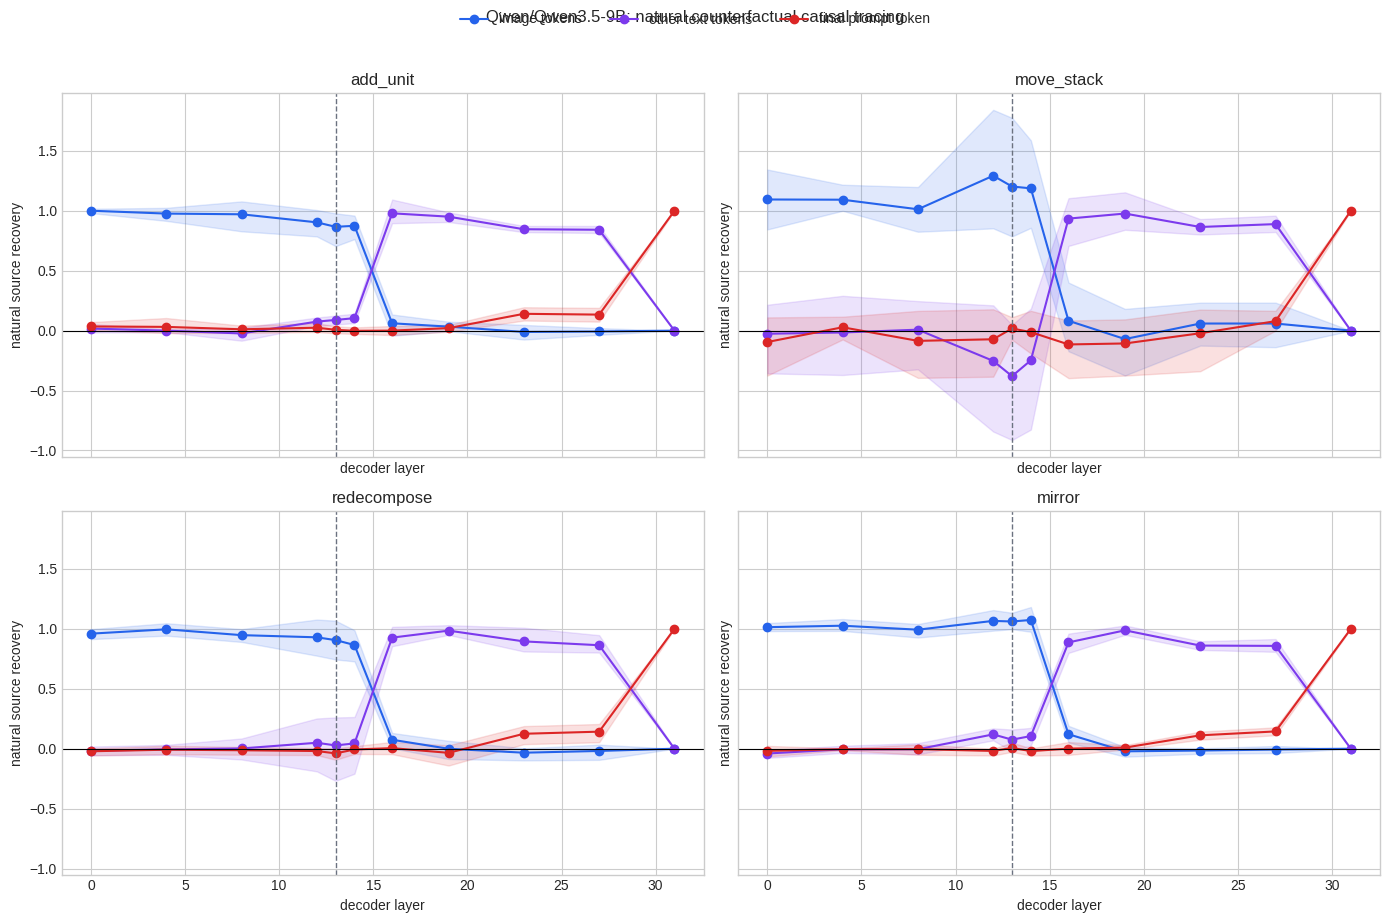

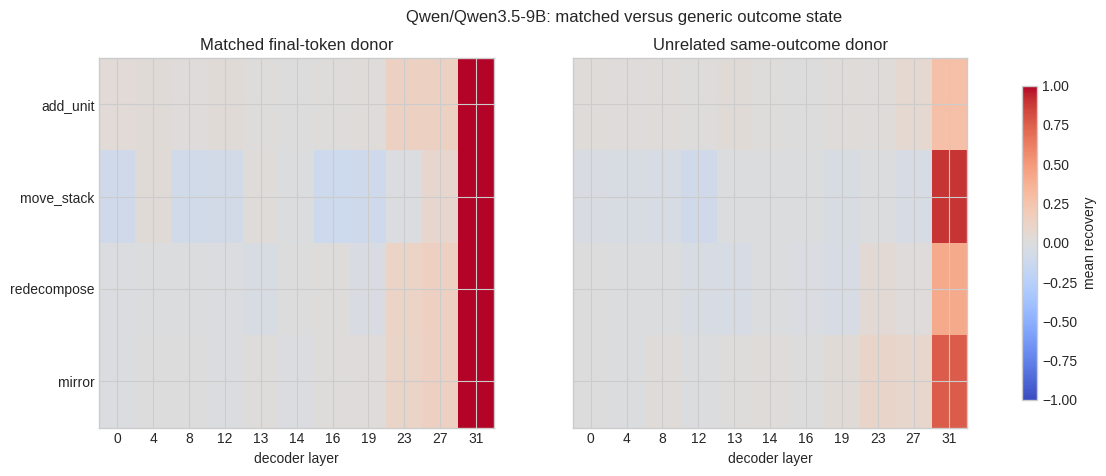

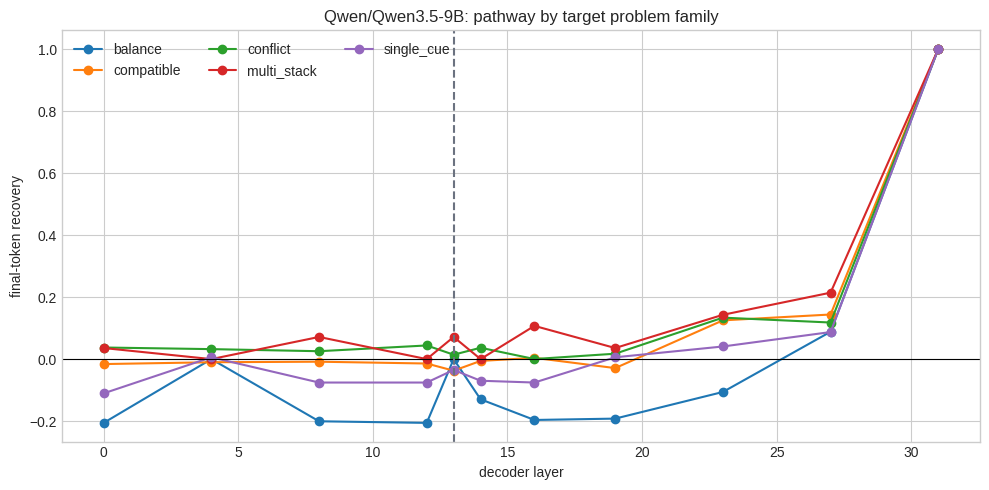

Figures saved to: /content/drive/MyDrive/VisualTorque/results/Qwen__Qwen3.5-9B/natural_counterfactual_causal_tracing_v1/analysis


In [16]:
%%cell_progress 15/16 Save causal tracing figures
cell_stage('Rendering layer curves and heatmaps')
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
scope_colors = {
    'matched_image_tokens': '#2563eb',
    'matched_other_text_tokens': '#7c3aed',
    'matched_final_prompt_token': '#dc2626',
}
scope_labels = {
    'matched_image_tokens': 'image tokens',
    'matched_other_text_tokens': 'other text tokens',
    'matched_final_prompt_token': 'final prompt token',
}

figure, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for axis, edit_type in zip(axes.flat, EDIT_TYPES):
    subset = matched_summary[matched_summary['edit_type'] == edit_type]
    for condition in scope_colors:
        curve = subset[subset['condition'] == condition].sort_values('layer_index')
        if curve.empty:
            continue
        x = curve['layer_index'].to_numpy()
        y = curve['recovery_mean'].to_numpy()
        axis.plot(
            x, y, marker='o', color=scope_colors[condition],
            label=scope_labels[condition],
        )
        axis.fill_between(
            x, curve['recovery_ci_low'], curve['recovery_ci_high'],
            color=scope_colors[condition], alpha=0.14,
        )
    axis.axhline(0, color='black', linewidth=0.8)
    axis.axvline(
        SELECTED_LAYER_INDEX, color='#6b7280', linestyle='--', linewidth=1
    )
    axis.set_title(edit_type)
    axis.set_xlabel('decoder layer')
    axis.set_ylabel('natural source recovery')
handles, labels = axes.flat[0].get_legend_handles_labels()
figure.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
figure.suptitle(f'{MODEL_ID}: natural counterfactual causal tracing', y=1.02)
figure.tight_layout()
figure.savefig(
    ANALYSIS_DIR / 'causal_tracing_by_edit.png', dpi=180, bbox_inches='tight'
)
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for axis, condition, title in (
    (axes[0], 'matched_final_prompt_token', 'Matched final-token donor'),
    (axes[1], 'control_same_source_outcome_final', 'Unrelated same-outcome donor'),
):
    subset = layer_summary[layer_summary['condition'] == condition]
    matrix = subset.pivot(
        index='edit_type', columns='layer_index', values='recovery_mean'
    ).reindex(index=EDIT_TYPES, columns=PATCH_LAYERS)
    image = axis.imshow(
        matrix.to_numpy(), aspect='auto', cmap='coolwarm', vmin=-1, vmax=1
    )
    axis.set_xticks(range(len(PATCH_LAYERS)), PATCH_LAYERS)
    axis.set_yticks(range(len(EDIT_TYPES)), EDIT_TYPES)
    axis.set_xlabel('decoder layer')
    axis.set_title(title)
figure.colorbar(image, ax=axes, label='mean recovery', shrink=0.85)
figure.suptitle(f'{MODEL_ID}: matched versus generic outcome state')
figure.savefig(
    ANALYSIS_DIR / 'matched_vs_generic_heatmap.png',
    dpi=180, bbox_inches='tight',
)
plt.show()

figure, axis = plt.subplots(figsize=(10, 5))
for strategy_name, group in strategy_frame[
    strategy_frame['condition'] == 'matched_final_prompt_token'
].groupby('strategy_group'):
    group = group.sort_values('layer_index')
    axis.plot(
        group['layer_index'], group['mean'], marker='o', label=strategy_name
    )
axis.axhline(0, color='black', linewidth=0.8)
axis.axvline(SELECTED_LAYER_INDEX, color='#6b7280', linestyle='--')
axis.set_xlabel('decoder layer')
axis.set_ylabel('final-token recovery')
axis.set_title(f'{MODEL_ID}: pathway by target problem family')
axis.legend(frameon=False, ncol=3)
figure.tight_layout()
figure.savefig(
    ANALYSIS_DIR / 'strategy_switching_curves.png',
    dpi=180, bbox_inches='tight',
)
plt.show()

diagnostic_summary = (
    diagnostic_frame.groupby(['edit_type', 'layer_index'])[
        ['final_token_delta_l2', 'image_mean_delta_l2']
    ].mean().reset_index()
)
diagnostic_summary.to_csv(
    ANALYSIS_DIR / 'activation_distance_summary.csv', index=False
)
print('Figures saved to:', ANALYSIS_DIR)


In [17]:
%%cell_progress 16/16 Write the mechanistic decision report
cell_stage('Summarizing what the pilot establishes and what comes next')

report_lines = [
    '# Natural counterfactual causal tracing report',
    '',
    f'- Model: `{MODEL_ID}`',
    f'- Revision: `{MODEL_REVISION}`',
    f'- Pairs: {len(pair_manifest)} ({PAIRS_PER_EDIT} per edit family)',
    f'- Layers: {PATCH_LAYERS}',
    f'- Selected representation layer: {SELECTED_LAYER_INDEX}',
    f'- Natural-effect threshold: {NATURAL_EFFECT_EPS}',
    '',
    '## Frozen interpretation',
    '',
    'Recovery measures movement toward the matched natural source output, not raw '
    'accuracy. Image-token recovery early and final-token recovery late is the '
    'predicted signature of information transfer from visual representation into '
    'the decision state. A same-source-outcome control that matches the final-token '
    'effect implies a generic outcome/answer state; a matched advantage implies '
    'pair-specific physical information.',
    '',
    '## Edit-family results',
    '',
]

mechanism_curves = {}
for edit_type in EDIT_TYPES:
    edit_summary = layer_summary[
        layer_summary['edit_type'] == edit_type
    ]
    report_lines.append(f'### {edit_type}')
    for condition in (
        'matched_image_tokens',
        'matched_final_prompt_token',
        'control_same_source_outcome_final',
    ):
        rows = edit_summary[edit_summary['condition'] == condition]
        if rows.empty or rows['recovery_mean'].isna().all():
            report_lines.append(f'- {condition}: insufficient natural output change.')
            continue
        best = rows.loc[rows['recovery_mean'].idxmax()]
        report_lines.append(
            f"- {condition}: peak mean recovery {best['recovery_mean']:.3f} "
            f"[{best['recovery_ci_low']:.3f}, {best['recovery_ci_high']:.3f}] "
            f"at layer {int(best['layer_index'])} (n={int(best['recovery_n_pairs'])})."
        )
    final_curve = edit_summary[
        edit_summary['condition'] == 'matched_final_prompt_token'
    ].sort_values('layer_index')
    image_curve = edit_summary[
        edit_summary['condition'] == 'matched_image_tokens'
    ].sort_values('layer_index')
    if len(final_curve) and len(image_curve):
        merged = final_curve[['layer_index', 'recovery_mean']].merge(
            image_curve[['layer_index', 'recovery_mean']],
            on='layer_index', suffixes=('_final', '_image')
        )
        crossover = merged[
            merged['recovery_mean_final'] >= merged['recovery_mean_image']
        ]
        if len(crossover):
            report_lines.append(
                f"- First sampled image-to-final crossover: layer "
                f"{int(crossover.iloc[0]['layer_index'])}."
            )
        else:
            report_lines.append('- No image-to-final crossover on the sampled grid.')
        mechanism_curves[edit_type] = final_curve.set_index('layer_index')[
            'recovery_mean'
        ].reindex(PATCH_LAYERS)
    report_lines.append('')

report_lines.extend([
    '## Cross-edit mechanism checks',
    '',
])
if {'add_unit', 'move_stack'} <= set(mechanism_curves):
    weight_curve = mechanism_curves['add_unit'].rank().to_numpy(dtype=float)
    distance_curve = mechanism_curves['move_stack'].rank().to_numpy(dtype=float)
    valid = np.isfinite(weight_curve) & np.isfinite(distance_curve)
    similarity = (
        float(np.corrcoef(weight_curve[valid], distance_curve[valid])[0, 1])
        if valid.sum() >= 3 else np.nan
    )
    report_lines.append(
        f'- Spearman-like rank correlation of add-unit and move-stack final-token '
        f'recovery curves: {similarity:.3f}. Similar curves support a shared late '
        'pathway; different curves support edit-specific strategies.'
    )

if len(control_frame):
    positive = control_frame[
        control_frame['control'] == 'control_same_target_outcome_final'
    ].sort_values('mean_gap', ascending=False)
    if len(positive):
        best = positive.iloc[0]
        report_lines.append(
            f"- Largest matched-minus-same-target control gap: "
            f"{best['mean_gap']:.3f} [{best['ci_low']:.3f}, "
            f"{best['ci_high']:.3f}] for {best['edit_type']} at layer "
            f"{int(best['layer_index'])}."
        )

redecompose_effect = layer_summary[
    (layer_summary['edit_type'] == 'redecompose')
    & (layer_summary['condition'] == 'matched_final_prompt_token')
]
if len(redecompose_effect):
    peak = redecompose_effect.loc[
        redecompose_effect['effect_norm_mean'].idxmax()
    ]
    report_lines.append(
        f"- Torque-preserving redecomposition peak raw final-token effect: "
        f"{peak['effect_norm_mean']:.3f} at layer {int(peak['layer_index'])}. "
        'A large late effect is evidence against complete torque abstraction.'
    )

report_lines.extend([
    '',
    '## Decision rule for the next notebook',
    '',
    '1. If matched final-token recovery is positive and exceeds the same-target '
    'control, decompose the crossover/peak layers into attention heads and MLPs '
    'with component-level path patching.',
    '2. If matched and same-source-outcome donors are equally effective only late, '
    'treat the late state as a generic answer representation and localize the '
    'physical computation in earlier image/text pathways.',
    '3. If add-unit and move-stack curves diverge, make strategy switching the '
    'central result and stratify component patching by conflict versus compatible '
    'problems.',
    '4. If redecomposition has a large late effect despite unchanged torque, test '
    'block-count, occupied-area, and distance-region patches as shortcut mediators.',
    '5. Only after the Qwen pattern passes controls should the identical frozen '
    'protocol be repeated on Gemma.',
    '',
    '## Limits',
    '',
    protocol_identity['interpretation_limit'],
    '',
])
report_path = ANALYSIS_DIR / 'causal_tracing_report.md'
report_path.write_text('\n'.join(report_lines), encoding='utf-8')

decision_summary = {
    'model_id': MODEL_ID,
    'resolved_revision': MODEL_REVISION,
    'selected_pairs': len(pair_manifest),
    'patch_layers': PATCH_LAYERS,
    'valid_recovery_pairs_by_edit': {
        edit_type: int(
            patch_frame[
                (patch_frame['edit_type'] == edit_type)
                & patch_frame['valid_recovery']
            ]['pair_id'].nunique()
        )
        for edit_type in EDIT_TYPES
    },
    'report_path': str(report_path),
    'recommended_next_experiment': (
        'component-level attention-head/MLP path patching at empirically identified '
        'crossover layers, stratified by edit and strategy group'
    ),
}
write_json_atomic(ANALYSIS_DIR / 'decision_summary.json', decision_summary)
print(report_path.read_text(encoding='utf-8'))
print('Completed:', MODEL_ID)


Write the mechanistic decision report:  94%|#########3| 15/16 [00:00<?, ?cell/s]

# Natural counterfactual causal tracing report

- Model: `Qwen/Qwen3.5-9B`
- Revision: `c202236235762e1c871ad0ccb60c8ee5ba337b9a`
- Pairs: 32 (8 per edit family)
- Layers: [0, 4, 8, 12, 13, 14, 16, 19, 23, 27, 31]
- Selected representation layer: 13
- Natural-effect threshold: 0.02

## Frozen interpretation

Recovery measures movement toward the matched natural source output, not raw accuracy. Image-token recovery early and final-token recovery late is the predicted signature of information transfer from visual representation into the decision state. A same-source-outcome control that matches the final-token effect implies a generic outcome/answer state; a matched advantage implies pair-specific physical information.

## Edit-family results

### add_unit
- matched_image_tokens: peak mean recovery 1.000 [0.981, 1.017] at layer 0 (n=8).
- matched_final_prompt_token: peak mean recovery 1.000 [1.000, 1.000] at layer 31 (n=8).
- control_same_source_outcome_final: peak mean recovery 0.277 [-